In [1]:
# 1. STANDARD LIBRARIES
import os
import sys

from pathlib import Path
from typing import Union, Dict, Tuple

# 2. DATA MANIPULATION AND NUMERICAL COMPUTATION
import pandas as pd
import numpy as np

# 3. DATA VISUALISATION
import matplotlib.pyplot as plt
import seaborn as sns

import plotly.graph_objects as go
import plotly.express as px

from sklearn.model_selection import TimeSeriesSplit

# 4. MACHINE LEARNING MODELS
from sklearn.ensemble import RandomForestRegressor as RF
from catboost import CatBoostRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

# 5. MODEL EVALUATION METRICS
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score,
)

# 6. HYPERPARAMETER OPTIMIZATION
import optuna

# 7. VISUALIZATION AND DISPLAY CONFIGURATION
# Consistent visualisation style
sns.set_theme(style="whitegrid", context="notebook")

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

# Enable inline Matplotlib plots in Jupyter 
%matplotlib inline

# 8. PROJECT CONFIGURATION
# Locate the project root
project_root = Path().resolve().parents[0]

# Set the working directory
os.chdir(project_root)

# Add the project root to the Python path
sys.path.append(str(project_root))

In [2]:
print(sys.executable)

c:\Users\George\boston-bike-demand-forecasting\.venv\Scripts\python.exe


## Preprocessing

In [3]:
# Loading the data
data = pd.read_parquet("./data/03_primary/blue_bike_boston_model.parquet")

In [4]:
data.shape

(17458, 19)

In [5]:
data.head(4)

,datetime,hour,day,weekday,weekend,holiday,month,year,temp_c,humidity,wind_kmh,pressure_hpa,weather,casual_duration,member_duration,total_duration,casual_riders,member_riders,total_riders
0,2022-01-01 00:00:00,0,1,5,1,1,1,2022,6.70,89.00,7.60,1014.90,Cloudy,554672.00,96509.00,651181.00,28,97,125
1,2022-01-01 01:00:00,1,1,5,1,1,1,2022,6.70,89.00,7.60,1014.70,Cloudy,46276.00,58472.00,104748.00,31,61,92
2,2022-01-01 02:00:00,2,1,5,1,1,1,2022,6.70,89.00,7.60,1014.70,Cloudy,377839.00,45191.00,423030.00,32,41,73
3,2022-01-01 03:00:00,3,1,5,1,1,1,2022,6.70,96.00,5.40,1014.20,Cloudy,2537734.00,37167.00,2574901.00,54,41,95


In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17458 entries, 0 to 17457
Data columns (total 19 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   datetime         17458 non-null  datetime64[us]
 1   hour             17458 non-null  int32         
 2   day              17458 non-null  int32         
 3   weekday          17458 non-null  int32         
 4   weekend          17458 non-null  int64         
 5   holiday          17458 non-null  int64         
 6   month            17458 non-null  int32         
 7   year             17458 non-null  int32         
 8   temp_c           17458 non-null  float64       
 9   humidity         17458 non-null  float64       
 10  wind_kmh         17458 non-null  float64       
 11  pressure_hpa     17458 non-null  float64       
 12  weather          17458 non-null  object        
 13  casual_duration  17458 non-null  float64       
 14  member_duration  17458 non-null  float

In [7]:
# Validate that datetime values are arranged in chronological order
print(data["datetime"].is_monotonic_increasing)

True


In [8]:
# Columns to be dropped from the dataset
columns_to_drop = [
    "datetime",
    "casual_riders",
    "member_riders",
    "casual_duration",
    "member_duration",
]

In [9]:
# Drop the specified columns from the dataset
data = data.drop(columns=columns_to_drop)

In [10]:
data.head(4)

,hour,day,weekday,weekend,holiday,month,year,temp_c,humidity,wind_kmh,pressure_hpa,weather,total_duration,total_riders
0,0,1,5,1,1,1,2022,6.70,89.00,7.60,1014.90,Cloudy,651181.00,125
1,1,1,5,1,1,1,2022,6.70,89.00,7.60,1014.70,Cloudy,104748.00,92
2,2,1,5,1,1,1,2022,6.70,89.00,7.60,1014.70,Cloudy,423030.00,73
3,3,1,5,1,1,1,2022,6.70,96.00,5.40,1014.20,Cloudy,2574901.00,95


In [11]:
data.columns

Index(['hour', 'day', 'weekday', 'weekend', 'holiday', 'month', 'year',
       'temp_c', 'humidity', 'wind_kmh', 'pressure_hpa', 'weather',
       'total_duration', 'total_riders'],
      dtype='object')

In [12]:
data.head(3)

,hour,day,weekday,weekend,holiday,month,year,temp_c,humidity,wind_kmh,pressure_hpa,weather,total_duration,total_riders
0,0,1,5,1,1,1,2022,6.70,89.00,7.60,1014.90,Cloudy,651181.00,125
1,1,1,5,1,1,1,2022,6.70,89.00,7.60,1014.70,Cloudy,104748.00,92
2,2,1,5,1,1,1,2022,6.70,89.00,7.60,1014.70,Cloudy,423030.00,73


In [13]:
# ONE-HOT ENCODING 

# Display the distinct weather categories present in the dataset.
print(data["weather"].unique())

# Count the occurrences of each weather category, including missing values.
print(data["weather"].value_counts(dropna=False))

['Cloudy' 'Rain' 'Snow' 'Fair' 'Clear']
weather
Cloudy    8212
Fair      5901
Rain      1956
Clear     1068
Snow       321
Name: count, dtype: int64


In [14]:
# Define the mapping for weather categories.
weather_mapping = {
    "Clear": 0,
    "Fair": 1,
    "Cloudy": 2,
    "Rain": 3,
    "Snow": 4
}

# Encode the weather column using the defined mapping.
data["weather"] = data["weather"].map(weather_mapping)

In [15]:
# Inspect the dataset's columns after encoding.
data.columns.tolist()

['hour',
 'day',
 'weekday',
 'weekend',
 'holiday',
 'month',
 'year',
 'temp_c',
 'humidity',
 'wind_kmh',
 'pressure_hpa',
 'weather',
 'total_duration',
 'total_riders']

In [16]:
data.head(3)

,hour,day,weekday,weekend,holiday,month,year,temp_c,humidity,wind_kmh,pressure_hpa,weather,total_duration,total_riders
0,0,1,5,1,1,1,2022,6.70,89.00,7.60,1014.90,2,651181.00,125
1,1,1,5,1,1,1,2022,6.70,89.00,7.60,1014.70,2,104748.00,92
2,2,1,5,1,1,1,2022,6.70,89.00,7.60,1014.70,2,423030.00,73


## Feature Engineering

In [17]:
# Create an independent copy of the dataset
df = data.copy()

In [18]:
df.head(4)

,hour,day,weekday,weekend,holiday,month,year,temp_c,humidity,wind_kmh,pressure_hpa,weather,total_duration,total_riders
0,0,1,5,1,1,1,2022,6.70,89.00,7.60,1014.90,2,651181.00,125
1,1,1,5,1,1,1,2022,6.70,89.00,7.60,1014.70,2,104748.00,92
2,2,1,5,1,1,1,2022,6.70,89.00,7.60,1014.70,2,423030.00,73
3,3,1,5,1,1,1,2022,6.70,96.00,5.40,1014.20,2,2574901.00,95


In [19]:
# Shift demand one hour backwards to create the next-hour target
df["target"] = df["total_riders"].shift(-1)

In [20]:
df.head(4)

,hour,day,weekday,weekend,holiday,month,year,temp_c,humidity,wind_kmh,pressure_hpa,weather,total_duration,total_riders,target
0,0,1,5,1,1,1,2022,6.70,89.00,7.60,1014.90,2,651181.00,125,92.00
1,1,1,5,1,1,1,2022,6.70,89.00,7.60,1014.70,2,104748.00,92,73.00
2,2,1,5,1,1,1,2022,6.70,89.00,7.60,1014.70,2,423030.00,73,95.00
3,3,1,5,1,1,1,2022,6.70,96.00,5.40,1014.20,2,2574901.00,95,91.00


In [21]:
df.tail(4)

,hour,day,weekday,weekend,holiday,month,year,temp_c,humidity,wind_kmh,pressure_hpa,weather,total_duration,total_riders,target
17454,20,31,6,1,0,12,2023,3.90,57.00,18.40,1012.90,1,109267.00,117,88.00
17455,21,31,6,1,0,12,2023,3.30,59.00,13.00,1013.20,1,418429.00,88,79.00
17456,22,31,6,1,0,12,2023,3.30,57.00,11.20,1013.60,2,80549.00,79,111.00
17457,23,31,6,1,0,12,2023,2.80,61.00,16.60,1014.40,2,163025.00,111,NaN


In [22]:
# Remove the final row because its next-hour demand is unknown
df = df.dropna(subset=["target"])

In [23]:
df.head(4)

,hour,day,weekday,weekend,holiday,month,year,temp_c,humidity,wind_kmh,pressure_hpa,weather,total_duration,total_riders,target
0,0,1,5,1,1,1,2022,6.70,89.00,7.60,1014.90,2,651181.00,125,92.00
1,1,1,5,1,1,1,2022,6.70,89.00,7.60,1014.70,2,104748.00,92,73.00
2,2,1,5,1,1,1,2022,6.70,89.00,7.60,1014.70,2,423030.00,73,95.00
3,3,1,5,1,1,1,2022,6.70,96.00,5.40,1014.20,2,2574901.00,95,91.00


In [24]:
df.tail(2)

,hour,day,weekday,weekend,holiday,month,year,temp_c,humidity,wind_kmh,pressure_hpa,weather,total_duration,total_riders,target
17455,21,31,6,1,0,12,2023,3.30,59.00,13.00,1013.20,1,418429.00,88,79.00
17456,22,31,6,1,0,12,2023,3.30,57.00,11.20,1013.60,2,80549.00,79,111.00


In [25]:
# Remove current cnt from the features
df.drop(columns=["total_riders"], inplace=True)

In [26]:
df.head(4)

,hour,day,weekday,weekend,holiday,month,year,temp_c,humidity,wind_kmh,pressure_hpa,weather,total_duration,target
0,0,1,5,1,1,1,2022,6.70,89.00,7.60,1014.90,2,651181.00,92.00
1,1,1,5,1,1,1,2022,6.70,89.00,7.60,1014.70,2,104748.00,73.00
2,2,1,5,1,1,1,2022,6.70,89.00,7.60,1014.70,2,423030.00,95.00
3,3,1,5,1,1,1,2022,6.70,96.00,5.40,1014.20,2,2574901.00,91.00


##  Dataset Preparation and Metric Computation

In [27]:
def prepare_dataset(
    df: pd.DataFrame,
    train_fraction: float = 0.80
) -> Tuple[
    pd.DataFrame, pd.DataFrame,
    pd.Series, pd.Series
]:
    """
    Split a time-series dataset into chronological training and testing sets.

    Parameters
    ----------
    df : pd.DataFrame
        Chronologically sorted dataset containing a 'target' column.
    train_fraction : float, default=0.80
        Proportion of observations allocated to training.

    Returns
    -------
    Tuple[pd.DataFrame, pd.DataFrame, pd.Series, pd.Series]
        Training features, testing features, training targets, and testing targets.

    Raises
    ------
    ValueError
        If the input dataset, target column, target values, or training
        fraction is invalid.
    """
    # Validate the training fraction.
    if not 0 < train_fraction < 1:
        raise ValueError("train_fraction must be strictly between 0 and 1.")

    # Validate the dataset and target column.
    if df.empty:
        raise ValueError("The input dataset must not be empty.")

    if "target" not in df.columns:
        raise ValueError("The dataset must contain a 'target' column.")

    if df["target"].isna().any():
        raise ValueError("The target column contains missing values.")

    # Separate predictors from the target variable.
    X = df.drop(columns=["target"])
    y = df["target"]

    # Calculate the chronological split index.
    train_end = int(len(df) * train_fraction)

    # Ensure both sets contain observations.
    if train_end == 0 or train_end == len(df):
        raise ValueError(
            "The training fraction must leave observations in both sets."
        )

    # Split the predictor features chronologically.
    X_train = X.iloc[:train_end].copy()
    X_test = X.iloc[train_end:].copy()

    # Split the target values using the same boundary.
    y_train = y.iloc[:train_end].copy()
    y_test = y.iloc[train_end:].copy()

    return X_train, X_test, y_train, y_test

In [28]:
def compute_metrics(
    y_true: Union[np.ndarray, list],
    y_pred: Union[np.ndarray, list]
) -> Dict[str, float]:
    """
    Compute regression evaluation metrics for bike-demand forecasting.

    Calculates MAE, RMSE, and R² to evaluate predicted rider counts
    against observed values.

    Parameters
    ----------
    y_true : array-like
        Actual target values.

    y_pred : array-like
        Predicted target values.

    Returns
    -------
    Dict[str, float]
        Dictionary containing MAE, RMSE, and R².
        MAE and RMSE are rounded to two decimal places,
        while R² is rounded to four decimal places.
    """
    # Convert inputs into NumPy arrays for consistent processing.
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    # Calculate the mean absolute prediction error.
    mae = mean_absolute_error(y_true, y_pred)

    # Calculate the root mean squared prediction error.
    rmse = root_mean_squared_error(y_true, y_pred)

    # Calculate the coefficient of determination.
    r2 = r2_score(y_true, y_pred)

    # Return the evaluation metrics with consistent rounding.
    return {
        "MAE": round(float(mae), 2),
        "RMSE": round(float(rmse), 2),
        "R²": round(float(r2), 4),
    }

## 1. Baseline Model  - Random Forest

## Training

In [29]:
# Split the dataset chronologically into training and testing sets.
X_train, X_test, y_train, y_test = prepare_dataset(
    df=df,
    train_fraction=0.80
)

In [30]:

# Initialize the Random Forest regression baseline.
model = RF(n_estimators=100, random_state=42, n_jobs=-1)

In [31]:
# Fit the model using the training dataset.
model.fit(X_train, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

## Inference

In [32]:
# Generate demand predictions for the test dataset.
y_pred = model.predict(X_test)

## Postprocessing

In [33]:
# Evaluate baseline performance using MAE, RMSE, and R².
metric_base = compute_metrics(y_test.values, y_pred)

# Display the evaluation metrics.
metric_base

{'MAE': 119.63, 'RMSE': 206.09, 'R²': 0.77}

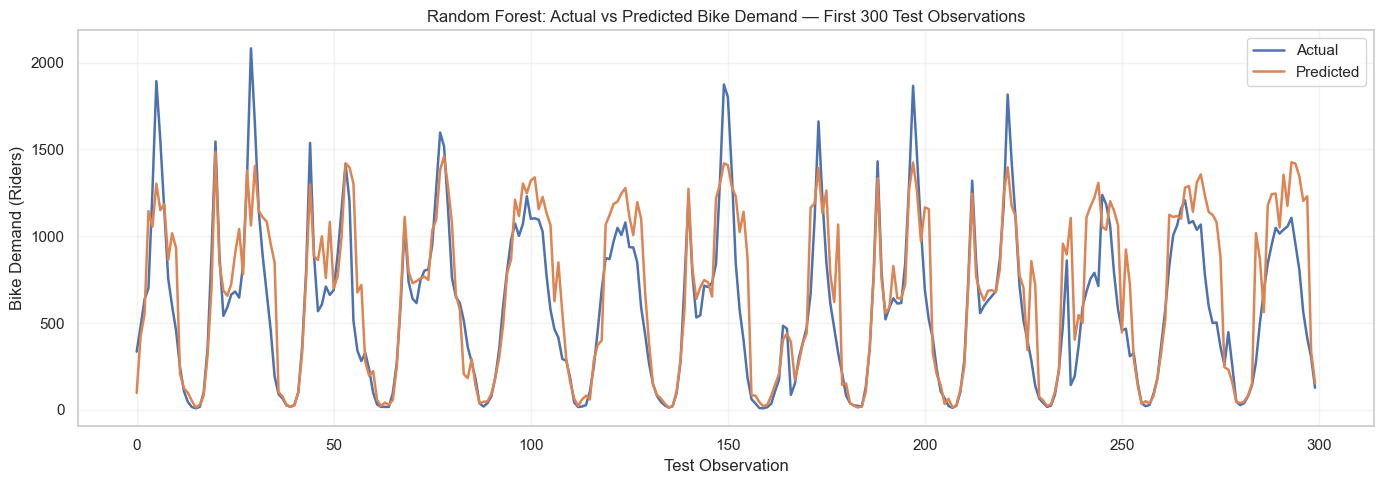

In [34]:
# Select the first 300 test observations for visualization.
n = 300

# Initialize the actual-versus-predicted demand plot.
plt.figure(figsize=(14, 5))

# Plot actual bike demand.
plt.plot(
    y_test.values[:n],
    label="Actual",
    linewidth=1.8
)

# Plot Random Forest predicted demand.
plt.plot(
    y_pred[:n],
    label="Predicted",
    linewidth=1.8
)

# Add descriptive labels and formatting.
plt.title("Random Forest: Actual vs Predicted Bike Demand — First 300 Test Observations")
plt.xlabel("Test Observation")
plt.ylabel("Bike Demand (Riders)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

# Display the comparison plot.
plt.show()

#### Key Observation

* Random Forest captures the overall demand pattern well but underpredicts sharp demand peaks and occasionally overestimates demand during lower-demand periods. This indicates that historical demand features (lags, rolling statistics, and EWM) may improve peak forecasting.

#### Recommendation

* Engineer lag features, rolling statistics, and exponentially weighted moving averages (EWM) to capture recent demand patterns and improve the model's ability to predict sudden demand fluctuations.


## 2. Baseline Model  - Random Forest + Target Lag features

In [35]:
# Calculate and display autocorrelation for lags 1–24.
for lag in range(1, 25):
    print(f"lag_{lag}: {df['target'].autocorr(lag=lag):.3f}")

lag_1: 0.896
lag_2: 0.715
lag_3: 0.547
lag_4: 0.403
lag_5: 0.267
lag_6: 0.140
lag_7: 0.042
lag_8: -0.009
lag_9: -0.040
lag_10: -0.108
lag_11: -0.186
lag_12: -0.222
lag_13: -0.194
lag_14: -0.124
lag_15: -0.058
lag_16: -0.021
lag_17: 0.036
lag_18: 0.131
lag_19: 0.249
lag_20: 0.372
lag_21: 0.497
lag_22: 0.637
lag_23: 0.781
lag_24: 0.857


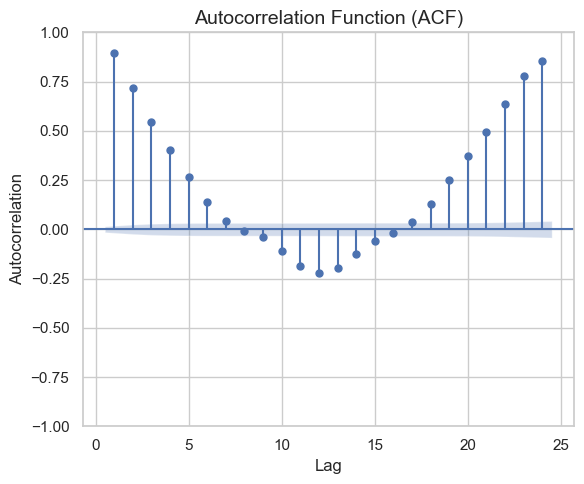

In [36]:
from statsmodels.graphics.tsaplots import plot_acf

# Plot ACF
fig, ax = plt.subplots(figsize=(6, 5))

plot_acf(
    df["target"].dropna(),
    lags=24,
    alpha=0.05,
    ax=ax,
    zero=False
)

ax.set_title("Autocorrelation Function (ACF)", fontsize=14)
ax.set_xlabel("Lag")
ax.set_ylabel("Autocorrelation")

plt.tight_layout()
plt.show()

## Feature Engineering

In [37]:
df = data.copy()

In [38]:
df.head(4)

,hour,day,weekday,weekend,holiday,month,year,temp_c,humidity,wind_kmh,pressure_hpa,weather,total_duration,total_riders
0,0,1,5,1,1,1,2022,6.70,89.00,7.60,1014.90,2,651181.00,125
1,1,1,5,1,1,1,2022,6.70,89.00,7.60,1014.70,2,104748.00,92
2,2,1,5,1,1,1,2022,6.70,89.00,7.60,1014.70,2,423030.00,73
3,3,1,5,1,1,1,2022,6.70,96.00,5.40,1014.20,2,2574901.00,95


In [39]:
# Shift demand one hour backwards to create the next-hour target
df["target"] = df["total_riders"].shift(-1)

In [40]:
df.head(4)

,hour,day,weekday,weekend,holiday,month,year,temp_c,humidity,wind_kmh,pressure_hpa,weather,total_duration,total_riders,target
0,0,1,5,1,1,1,2022,6.70,89.00,7.60,1014.90,2,651181.00,125,92.00
1,1,1,5,1,1,1,2022,6.70,89.00,7.60,1014.70,2,104748.00,92,73.00
2,2,1,5,1,1,1,2022,6.70,89.00,7.60,1014.70,2,423030.00,73,95.00
3,3,1,5,1,1,1,2022,6.70,96.00,5.40,1014.20,2,2574901.00,95,91.00


In [41]:
# Create short-term demand lags: 1 and 2 hours
for i in range(1, 4):
    df[f"rider_lag_{i}"] = df["total_riders"].shift(i)

# Create daily-cycle demand lags: 21 to 24 hours
for i in range(22, 25):
    df[f"rider_lag_{i}"] = df["total_riders"].shift(i)

In [42]:
# Remove rows made incomplete by target and lag creation
df = df.dropna().copy()

In [43]:
df.head(3)

,hour,day,weekday,weekend,holiday,month,year,temp_c,humidity,wind_kmh,pressure_hpa,weather,total_duration,total_riders,target,rider_lag_1,rider_lag_2,rider_lag_3,rider_lag_22,rider_lag_23,rider_lag_24
24,0,2,6,1,0,1,2022,9.40,100.00,5.40,1006.80,2,105878.00,103,61.00,123.00,127.00,146.00,73.00,92.00,125.00
25,1,2,6,1,0,1,2022,9.40,97.00,5.40,1006.80,3,56702.00,61,64.00,103.00,123.00,127.00,95.00,73.00,92.00
26,2,2,6,1,0,1,2022,8.90,96.00,7.60,1005.80,3,160263.00,64,42.00,61.00,103.00,123.00,91.00,95.00,73.00


## Training

In [44]:
# Split the dataset chronologically into training and testing sets.
X_train, X_test, y_train, y_test = prepare_dataset(
    df=df,
    train_fraction=0.80
)

In [45]:

# Initialize the Random Forest regression baseline.
model = RF(n_estimators=100, random_state=42, n_jobs=-1)

In [46]:
# Fit the model using the training dataset.
model.fit(X_train, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

## Inference

In [47]:
# Generate demand predictions for the test dataset.
y_pred = model.predict(X_test)

## Postprocessing

In [48]:
# Evaluate baseline performance using MAE, RMSE, and R².
metric_target_lag = compute_metrics(y_test.values, y_pred)

# Display the evaluation metrics.
metric_target_lag

{'MAE': 52.09, 'RMSE': 91.31, 'R²': 0.9549}

In [49]:
print('Baseline model scores:', metric_base)
print('Baseline model with target lags scores:', metric_target_lag)

Baseline model scores: {'MAE': 119.63, 'RMSE': 206.09, 'R²': 0.77}
Baseline model with target lags scores: {'MAE': 52.09, 'RMSE': 91.31, 'R²': 0.9549}


## 2. CatBoostRegressor Model

### Feature Engineering

In [50]:
df = data.copy()

In [51]:
# Define the reverse mapping.
reverse_weather_mapping = {
    0: "Clear",
    1: "Fair",
    2: "Cloudy",
    3: "Rain",
    4: "Snow"
}

# Restore the original weather categories.
df["weather"] = df["weather"].map(reverse_weather_mapping)

In [52]:
# Check the restored weather categories.
print(df["weather"].unique())

# Check for missing values introduced by the reverse mapping.
print("Missing weather values:", df["weather"].isna().sum())

['Cloudy' 'Rain' 'Snow' 'Fair' 'Clear']
Missing weather values: 0


In [53]:
# Check the data type of the weather column.
df["weather"].dtype

dtype('O')

In [54]:
df.head(4)

,hour,day,weekday,weekend,holiday,month,year,temp_c,humidity,wind_kmh,pressure_hpa,weather,total_duration,total_riders
0,0,1,5,1,1,1,2022,6.70,89.00,7.60,1014.90,Cloudy,651181.00,125
1,1,1,5,1,1,1,2022,6.70,89.00,7.60,1014.70,Cloudy,104748.00,92
2,2,1,5,1,1,1,2022,6.70,89.00,7.60,1014.70,Cloudy,423030.00,73
3,3,1,5,1,1,1,2022,6.70,96.00,5.40,1014.20,Cloudy,2574901.00,95


In [55]:
# Shift demand one hour backwards to create the next-hour target
df["target"] = df["total_riders"].shift(-1)

In [56]:
# Create short-term demand lags: 1 and 2 hours
for i in range(1, 4):
    df[f"rider_lag_{i}"] = df["total_riders"].shift(i)

# Create daily-cycle demand lags: 21 to 24 hours
for i in range(22, 25):
    df[f"rider_lag_{i}"] = df["total_riders"].shift(i)

In [57]:
# Remove rows made incomplete by target and lag creation
df = df.dropna().copy()

In [58]:
df.head(4)

,hour,day,weekday,weekend,holiday,month,year,temp_c,humidity,wind_kmh,pressure_hpa,weather,total_duration,total_riders,target,rider_lag_1,rider_lag_2,rider_lag_3,rider_lag_22,rider_lag_23,rider_lag_24
24,0,2,6,1,0,1,2022,9.40,100.00,5.40,1006.80,Cloudy,105878.00,103,61.00,123.00,127.00,146.00,73.00,92.00,125.00
25,1,2,6,1,0,1,2022,9.40,97.00,5.40,1006.80,Rain,56702.00,61,64.00,103.00,123.00,127.00,95.00,73.00,92.00
26,2,2,6,1,0,1,2022,8.90,96.00,7.60,1005.80,Rain,160263.00,64,42.00,61.00,103.00,123.00,91.00,95.00,73.00
27,3,2,6,1,0,1,2022,8.90,96.00,0.00,1005.20,Rain,169622.00,42,28.00,64.00,61.00,103.00,124.00,91.00,95.00


### Training

In [59]:
# Split the dataset chronologically into training and testing sets.
X_train, X_test, y_train, y_test = prepare_dataset(
    df=df,
    train_fraction=0.80
)

In [60]:
# Identify categorical feature.
cat_features = ["weather"]


# Create the CatBoost model.
model = CatBoostRegressor(
    loss_function="RMSE",
    random_seed=42,
    verbose=False
)

# Train the model.
model.fit(
    X_train,
    y_train,
    cat_features=cat_features
)

CatBoostRegressor(loss_function='RMSE', random_seed=42, verbose=False)

### Inference

In [61]:
# Generate demand predictions for the test dataset.
y_pred = model.predict(X_test)

### Postprocessing

In [62]:
# Evaluate baseline performance using MAE, RMSE, and R².
catboost_metrics = compute_metrics(y_test.values, y_pred)

# Display the evaluation metrics.
catboost_metrics

{'MAE': 47.56, 'RMSE': 80.61, 'R²': 0.9648}

In [63]:
print('Baseline model scores:', metric_base)
print('Baseline model with target lags scores:', metric_target_lag)
print('Catboost Regressor model score:', catboost_metrics)


Baseline model scores: {'MAE': 119.63, 'RMSE': 206.09, 'R²': 0.77}
Baseline model with target lags scores: {'MAE': 52.09, 'RMSE': 91.31, 'R²': 0.9549}
Catboost Regressor model score: {'MAE': 47.56, 'RMSE': 80.61, 'R²': 0.9648}



**CatBoost is the current leading model**, achieving an MAE of 47.56, RMSE of 80.61, and R² of 0.9648. We will proceed with CatBoost optimization.

## 2. CatBoostRegressor Model + More Engineering

In [110]:
# Create an independent copy of the dataset
df = data.copy()

In [111]:
# Define the reverse mapping.
reverse_weather_mapping = {
    0: "Clear",
    1: "Fair",
    2: "Cloudy",
    3: "Rain",
    4: "Snow"
}

# Restore the original weather categories.
df["weather"] = df["weather"].map(reverse_weather_mapping)

In [112]:
# Check the restored weather categories.
print(df["weather"].unique())

# Check for missing values introduced by the reverse mapping.
print("Missing weather values:", df["weather"].isna().sum())

['Cloudy' 'Rain' 'Snow' 'Fair' 'Clear']
Missing weather values: 0


In [113]:
# Check the data type of the weather column.
df["weather"].dtype

dtype('O')

In [114]:
df.head(4)

,hour,day,weekday,weekend,holiday,month,year,temp_c,humidity,wind_kmh,pressure_hpa,weather,total_duration,total_riders
0,0,1,5,1,1,1,2022,6.70,89.00,7.60,1014.90,Cloudy,651181.00,125
1,1,1,5,1,1,1,2022,6.70,89.00,7.60,1014.70,Cloudy,104748.00,92
2,2,1,5,1,1,1,2022,6.70,89.00,7.60,1014.70,Cloudy,423030.00,73
3,3,1,5,1,1,1,2022,6.70,96.00,5.40,1014.20,Cloudy,2574901.00,95


In [115]:
# Shift demand one hour backwards to create the next-hour target
df["target"] = df["total_riders"].shift(-1).ffill()

In [116]:
# Create short-term demand lags: 1 and 2 hours
for i in range(1, 4):
    df[f"rider_lag_{i}"] = df["total_riders"].shift(i).bfill()

# Create daily-cycle demand lags: 21 to 24 hours
for i in range(22, 25):
    df[f"rider_lag_{i}"] = df["total_riders"].shift(i).bfill()

In [ ]:
# Remove rows made incomplete by target and lag creation
#df = df.dropna().copy()

In [117]:
# Create a feature representing the change in demand
# from the previous hour
df["riders_change_1"] = (
    df["total_riders"] - df["rider_lag_1"]
)

In [118]:
df.head(4)

,hour,day,weekday,weekend,holiday,month,year,temp_c,humidity,wind_kmh,pressure_hpa,weather,total_duration,total_riders,target,rider_lag_1,rider_lag_2,rider_lag_3,rider_lag_22,rider_lag_23,rider_lag_24,riders_change_1
0,0,1,5,1,1,1,2022,6.70,89.00,7.60,1014.90,Cloudy,651181.00,125,92.00,125.00,125.00,125.00,125.00,125.00,125.00,0.00
1,1,1,5,1,1,1,2022,6.70,89.00,7.60,1014.70,Cloudy,104748.00,92,73.00,125.00,125.00,125.00,125.00,125.00,125.00,-33.00
2,2,1,5,1,1,1,2022,6.70,89.00,7.60,1014.70,Cloudy,423030.00,73,95.00,92.00,125.00,125.00,125.00,125.00,125.00,-19.00
3,3,1,5,1,1,1,2022,6.70,96.00,5.40,1014.20,Cloudy,2574901.00,95,91.00,73.00,92.00,125.00,125.00,125.00,125.00,22.00


### Training

In [119]:
# Split the dataset chronologically into training and testing sets.
X_train, X_test, y_train, y_test = prepare_dataset(
    df=df,
    train_fraction=0.80
)

In [120]:
# Identify categorical feature.
cat_features = ["weather"]


# Create the CatBoost model.
model = CatBoostRegressor(
    loss_function="RMSE",
    random_seed=42,
    verbose=False
)

# Train the model.
model.fit(
    X_train,
    y_train,
    cat_features=cat_features
)

CatBoostRegressor(loss_function='RMSE', random_seed=42, verbose=False)

### Inference

In [121]:
# Generate demand predictions for the test dataset.
y_pred = model.predict(X_test)

### Postprocessing

In [122]:
# Evaluate baseline performance using MAE, RMSE, and R².
catboost_metrics_final = compute_metrics(y_test.values, y_pred)

# Display the evaluation metrics.
catboost_metrics_final

{'MAE': 46.95, 'RMSE': 78.75, 'R²': 0.9664}

In [123]:
print('Baseline model scores:', metric_base)
print('Baseline model with target lags scores:', metric_target_lag)
print('Catboost Regressor model score:', catboost_metrics)
print('Catboost Regressor model final score:', catboost_metrics_final)


Baseline model scores: {'MAE': 119.63, 'RMSE': 206.09, 'R²': 0.77}
Baseline model with target lags scores: {'MAE': 52.09, 'RMSE': 91.31, 'R²': 0.9549}
Catboost Regressor model score: {'MAE': 47.56, 'RMSE': 80.61, 'R²': 0.9648}
Catboost Regressor model final score: {'MAE': 46.95, 'RMSE': 78.75, 'R²': 0.9664}


#### Conclusion

The following engineered features were evaluated: rolling statistics, cyclical time encoding, peak-hour indicators, weekend-hour interactions, weekly demand lags, weather–temperature interactions, and weather lag features. None improved the baseline model consistently.

The best performance remains **MAE = 46.05, RMSE = 77.93, and R² = 0.9671**.

#### Next Step

Proceed with **CatBoost hyperparameter tuning** to optimise model performance while maintaining the same chronological train-test split.


### Gradient Boosting with Hyperparameters Tuning(Optuna)

In [124]:
df.head(4)

,hour,day,weekday,weekend,holiday,month,year,temp_c,humidity,wind_kmh,pressure_hpa,weather,total_duration,total_riders,target,rider_lag_1,rider_lag_2,rider_lag_3,rider_lag_22,rider_lag_23,rider_lag_24,riders_change_1
0,0,1,5,1,1,1,2022,6.70,89.00,7.60,1014.90,Cloudy,651181.00,125,92.00,125.00,125.00,125.00,125.00,125.00,125.00,0.00
1,1,1,5,1,1,1,2022,6.70,89.00,7.60,1014.70,Cloudy,104748.00,92,73.00,125.00,125.00,125.00,125.00,125.00,125.00,-33.00
2,2,1,5,1,1,1,2022,6.70,89.00,7.60,1014.70,Cloudy,423030.00,73,95.00,92.00,125.00,125.00,125.00,125.00,125.00,-19.00
3,3,1,5,1,1,1,2022,6.70,96.00,5.40,1014.20,Cloudy,2574901.00,95,91.00,73.00,92.00,125.00,125.00,125.00,125.00,22.00


In [125]:
# Reset the index after removing rows
df.reset_index(drop=True, inplace=True)

In [126]:
X_train, X_test, y_train, y_test = prepare_dataset(df, train_fraction=0.8)

In [127]:
X_train

,hour,day,weekday,weekend,holiday,month,year,temp_c,humidity,wind_kmh,pressure_hpa,weather,total_duration,total_riders,rider_lag_1,rider_lag_2,rider_lag_3,rider_lag_22,rider_lag_23,rider_lag_24,riders_change_1
0,0,1,5,1,1,1,2022,6.70,89.00,7.60,1014.90,Cloudy,651181.00,125,125.00,125.00,125.00,125.00,125.00,125.00,0.00
1,1,1,5,1,1,1,2022,6.70,89.00,7.60,1014.70,Cloudy,104748.00,92,125.00,125.00,125.00,125.00,125.00,125.00,-33.00
2,2,1,5,1,1,1,2022,6.70,89.00,7.60,1014.70,Cloudy,423030.00,73,92.00,125.00,125.00,125.00,125.00,125.00,-19.00
3,3,1,5,1,1,1,2022,6.70,96.00,5.40,1014.20,Cloudy,2574901.00,95,73.00,92.00,125.00,125.00,125.00,125.00,22.00
4,4,1,5,1,1,1,2022,7.20,93.00,5.40,1014.40,Cloudy,954626.00,91,95.00,73.00,92.00,125.00,125.00,125.00,-4.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13961,7,8,1,0,0,8,2023,18.90,96.00,9.40,1007.50,Rain,444169.00,575,248.00,81.00,12.00,673.00,1104.00,732.00,327.00
13962,8,8,1,0,0,8,2023,20.00,96.00,14.80,1006.80,Rain,874650.00,1103,575.00,248.00,81.00,400.00,673.00,1104.00,528.00
13963,9,8,1,0,0,8,2023,20.00,96.00,16.60,1006.20,Rain,529676.00,655,1103.00,575.00,248.00,316.00,400.00,673.00,-448.00
13964,10,8,1,0,0,8,2023,20.00,96.00,13.00,1005.70,Rain,39016.00,58,655.00,1103.00,575.00,520.00,316.00,400.00,-597.00


In [128]:
# Identify categorical features in the dataset.
cat_features = ["weather"]

In [129]:
#  Define the Optuna objective function using a chronological split.

def objective(trial):
    np.random.seed(42)  # Ensure reproducibility for each trial
    # Define the hyperparameter search space.
    params = {
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2),
        "depth": trial.suggest_int("depth", 3, 8),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 0.5, 5.0),
        "iterations": 1000,
        "loss_function": "RMSE",
        "verbose": 0,

    }

    # Split training data chronologically into training and validation sets.
    train_idx = int(0.85 * len(X_train))


    # Create chronological training and validation sets.
    x_tr = X_train.iloc[:train_idx]
    x_val = X_train.iloc[train_idx :]

    y_tr = y_train.iloc[:train_idx]
    y_val = y_train.iloc[train_idx :]

    # Initialise the CatBoost model.
    model = CatBoostRegressor(**params, random_seed=42)

    # Train with early stopping using validation RMSE.
    model.fit(
        x_tr,
        y_tr,
        cat_features=cat_features,
        eval_set=(x_val, y_val),
        early_stopping_rounds=100,
        use_best_model=True,
    )

    # Generate predictions for the validation set.
    preds = model.predict(x_val)

    # Calculate validation RMSE.
    rmse = root_mean_squared_error(y_val, preds)

    # Record the best iteration for later model training.
    trial.set_user_attr(
        "best_iteration",
        model.get_best_iteration()
    )

    return rmse

In [130]:
# Create Optuna study
study = optuna.create_study(
    direction="minimize",
    study_name="bike_catboost_optimization",
    sampler=optuna.samplers.TPESampler(
        seed=42
    )
)
# Run hyperparameter optimisation
study.optimize(
    objective,
    n_trials=150,
    show_progress_bar=True
)

# Display the best results.
print("Best validation RMSE:", study.best_value)
print("Best hyperparameters:", study.best_params)
print(
    "Best iteration:",
    study.best_trial.user_attrs["best_iteration"]
)

[I 2026-10-25 17:12:12,995] A new study created in memory with name: bike_catboost_optimization


  0%|          | 0/150 [00:00<?, ?it/s]

[I 2026-10-25 17:13:33,707] Trial 0 finished with value: 100.82436294592068 and parameters: {'learning_rate': 0.08116262258099886, 'depth': 8, 'l2_leaf_reg': 3.793972738151323}. Best is trial 0 with value: 100.82436294592068.
[I 2026-10-25 17:13:56,889] Trial 1 finished with value: 112.74160988361999 and parameters: {'learning_rate': 0.12374511199743694, 'depth': 3, 'l2_leaf_reg': 1.201975341512912}. Best is trial 0 with value: 100.82436294592068.
[I 2026-10-25 17:15:18,889] Trial 2 finished with value: 106.06665035992793 and parameters: {'learning_rate': 0.021035886311957897, 'depth': 8, 'l2_leaf_reg': 3.20501755284444}. Best is trial 0 with value: 100.82436294592068.
[I 2026-10-25 17:15:48,175] Trial 3 finished with value: 109.10793400265892 and parameters: {'learning_rate': 0.14453378978124864, 'depth': 3, 'l2_leaf_reg': 4.864594334728975}. Best is trial 0 with value: 100.82436294592068.
[I 2026-10-25 17:16:25,709] Trial 4 finished with value: 105.37224913852482 and parameters: {'le

In [131]:
best_params = study.best_trial.params

In [132]:
best_trial = study.best_trial
print("BEST RMSE:", best_trial.value)
print("Best iteration (trees):", best_trial.user_attrs["best_iteration"])

BEST RMSE: 99.1908824088814
Best iteration (trees): 966


In [133]:
best_params.update({
    "iterations": best_trial.user_attrs["best_iteration"],
    "loss_function": "RMSE",
    "verbose": 0
})

In [134]:
final_model = CatBoostRegressor(**best_params)
final_model.fit(X_train, y_train,cat_features = [
    "weather"] )

CatBoostRegressor(depth=7, iterations=966, l2_leaf_reg=1.3985320197126188, learning_rate=0.09665329700123683, loss_function='RMSE', verbose=0)

In [135]:
# Step 5: Predict on x_test and evaluate
y_pred = final_model.predict(X_test)

In [137]:
metrics_catbost_tuned = compute_metrics(y_test.values, y_pred)
metrics_catbost_tuned

{'MAE': 45.63, 'RMSE': 78.21, 'R²': 0.9669}

In [138]:
print('Baseline model scores:', metric_base)
print('Baseline model with target lags scores:', metric_target_lag)
print('Catboost Regressor model score:', catboost_metrics)
print('Catboost Regressor model final score:', catboost_metrics_final)
print('Tuned Catboost Regressor model score:', metrics_catbost_tuned)

Baseline model scores: {'MAE': 119.63, 'RMSE': 206.09, 'R²': 0.77}
Baseline model with target lags scores: {'MAE': 52.09, 'RMSE': 91.31, 'R²': 0.9549}
Catboost Regressor model score: {'MAE': 47.56, 'RMSE': 80.61, 'R²': 0.9648}
Catboost Regressor model final score: {'MAE': 46.95, 'RMSE': 78.75, 'R²': 0.9664}
Tuned Catboost Regressor model score: {'MAE': 45.63, 'RMSE': 78.21, 'R²': 0.9669}


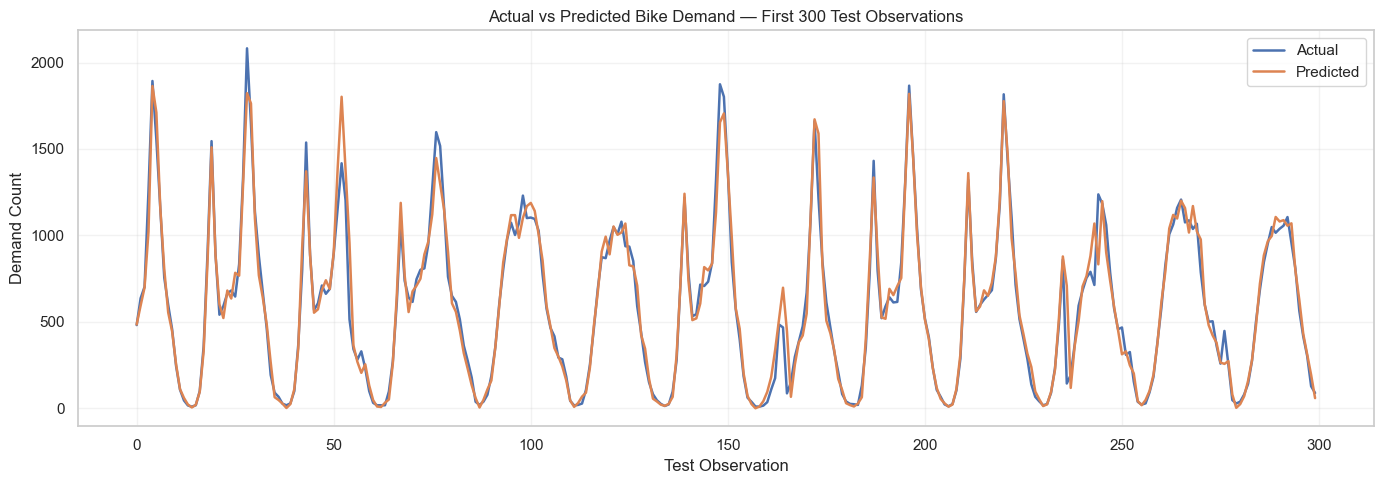

In [139]:
n = 300

plt.figure(figsize=(14, 5))

plt.plot(
    y_test.values[:n],
    label="Actual",
    linewidth=1.8
)

plt.plot(
    y_pred[:n],
    label="Predicted",
    linewidth=1.8
)

plt.title("Actual vs Predicted Bike Demand — First 300 Test Observations")
plt.xlabel("Test Observation")
plt.ylabel("Demand Count")

plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

plt.show()

### MLflow Experiment Tracking

#### 1. MLflow configuration

In [ ]:
from pathlib import Path
import mlflow


# Define the project root
PROJECT_ROOT = Path.cwd().resolve()

# Handle execution from the notebooks directory.
if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent


#Configure MLflow storage
# SQLite database for experiment metadata.
MLFLOW_DB_PATH = PROJECT_ROOT / "mlflow.db"

# Directory for model artefacts.
MLFLOW_ARTIFACT_DIR = PROJECT_ROOT / "mlruns"
MLFLOW_ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

# Convert the database path to a Windows-compatible SQLite URI.
MLFLOW_TRACKING_URI = f"sqlite:///{MLFLOW_DB_PATH.as_posix()}"

# Configure MLflow BEFORE creating or selecting experiments.
mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)


# 3. Create or select the experiment
EXPERIMENT_NAME = "Boston_Bike_Demand_Forecasting"

mlflow.set_experiment(EXPERIMENT_NAME)


# 4. Verify the configuration
experiment = mlflow.get_experiment_by_name(EXPERIMENT_NAME)

print("MLflow configured successfully!")
print("-" * 45)
print("Experiment:", experiment.name)
print("Experiment ID:", experiment.experiment_id)
print("Tracking URI:", mlflow.get_tracking_uri())
print("Database:", MLFLOW_DB_PATH)
print("Artefact directory:", MLFLOW_ARTIFACT_DIR)

2026/10/25 21:07:07 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/25 21:07:07 INFO mlflow.store.db.utils: Updating database tables
2026/10/25 21:07:11 INFO mlflow.tracking.fluent: Experiment with name 'Boston_Bike_Demand_Forecasting' does not exist. Creating a new experiment.


MLflow configured successfully!
---------------------------------------------
Experiment: Boston_Bike_Demand_Forecasting
Experiment ID: 1
Tracking URI: sqlite:///C:/Users/George/boston-bike-demand-forecasting/mlflow.db
Database: C:\Users\George\boston-bike-demand-forecasting\mlflow.db
Artefact directory: C:\Users\George\boston-bike-demand-forecasting\mlruns


In [145]:
# Define the model directory.
MODEL_DIR = PROJECT_ROOT / "data" / "06_models"

# Create the directory if it does not exist.
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Define the native CatBoost model path.
MODEL_PATH = MODEL_DIR / "first_catboost_model.cbm"

# Save the existing trained model.
final_model.save_model(str(MODEL_PATH))

# Verify that the model exists.
if MODEL_PATH.exists():
    print("CatBoost model saved successfully!")
    print("Model path:", MODEL_PATH)
    print(f"File size: {MODEL_PATH.stat().st_size / 1024:.2f} KB")
else:
    raise FileNotFoundError("The CatBoost model was not saved.")

CatBoost model saved successfully!
Model path: C:\Users\George\boston-bike-demand-forecasting\data\06_models\first_catboost_model.cbm
File size: 2033.26 KB


#### 2. Save the model and calculate evaluation metrics

In [146]:
# Generate predictions using the existing trained model.
y_pred = final_model.predict(X_test)

# Calculate the test-set evaluation metrics.
test_metrics = {
    "test_mae": float(mean_absolute_error(y_test, y_pred)),
    "test_rmse": float(root_mean_squared_error(y_test, y_pred)),
    "test_r2": float(r2_score(y_test, y_pred))
}

# Display the results.
print("Final CatBoost Test Metrics")
print("-" * 35)

for metric, value in test_metrics.items():
    print(f"{metric}: {value:.4f}")

Final CatBoost Test Metrics
-----------------------------------
test_mae: 45.6340
test_rmse: 78.2050
test_r2: 0.9669


#### 3. Log the experiment to MLflow

In [147]:
import mlflow
import mlflow.catboost

from mlflow.models import infer_signature

# Ensure the correct experiment is selected.
mlflow.set_experiment(EXPERIMENT_NAME)

# Create an example input and its corresponding prediction.
input_example = X_train.head(5).copy()
output_example = final_model.predict(input_example)

# Infer the model signature.
signature = infer_signature(
    input_example,
    output_example
)

# Retrieve the parameters of the trained model.
model_params = final_model.get_params()

# Retrieve the best iteration selected by Optuna.
best_iteration = best_trial.user_attrs.get("best_iteration")

# Start an MLflow run.
with mlflow.start_run(
    run_name="CatBoost_Optuna_Tuned_Final"
) as run:

    # 1. Log CatBoost parameters.
    mlflow.log_params({
        key: value
        for key, value in model_params.items()
        if value is not None
        and isinstance(value, (str, int, float, bool))
    })

    # 2. Log Optuna optimisation details.
    mlflow.log_param("tuning_method", "Optuna_TPE")
    mlflow.log_param("optuna_trials", len(study.trials))
    mlflow.log_param("validation_fraction", 0.15)
    mlflow.log_param("validation_strategy", "Chronological split")

    # Record the best validation RMSE.
    mlflow.log_metric(
        "best_validation_rmse",
        float(study.best_value)
    )

    # Record the best iteration.
    if best_iteration is not None:
        mlflow.log_param(
            "optuna_best_iteration",
            int(best_iteration)
        )

    # Log the best Optuna hyperparameters.
    for key, value in study.best_params.items():
        mlflow.log_param(f"optuna_{key}", value)

    # 3. Log final test-set metrics.
    mlflow.log_metrics(test_metrics)

    # 4. Log dataset and model information.
    mlflow.log_params({
        "training_rows": int(len(X_train)),
        "test_rows": int(len(X_test)),
        "feature_count": int(X_train.shape[1]),
        "random_seed": 42
    })

    # 5. Add descriptive tags.
    mlflow.set_tags({
        "project": "Boston Blue Bike Demand Forecasting",
        "model_type": "CatBoostRegressor",
        "tuning_method": "Optuna",
        "evaluation_strategy": "Chronological holdout test set",
        "model_status": "Evaluated"
    })

    # 6. Log the native CatBoost file.
    mlflow.log_artifact(
        str(MODEL_PATH),
        artifact_path="native_model"
    )

    # 7. Log the model in MLflow format.
    mlflow.catboost.log_model(
        cb_model=final_model,
        name="catboost_model",
        signature=signature,
        input_example=input_example
    )

    # 8. Capture the run ID.
    run_id = run.info.run_id

    print("MLflow run completed successfully!")
    print("-" * 40)
    print("Experiment:", EXPERIMENT_NAME)
    print("Run ID:", run_id)
    print("Native model:", MODEL_PATH)
    print("Test metrics:", test_metrics)

c:\Users\George\boston-bike-demand-forecasting\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/10/25 21:11:21 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in C:\Users\George\boston-bike-demand-forecasting
2026/10/25 21:11:22 INFO mlflow.utils.uv_utils: Detected uv proje

MLflow run completed successfully!
----------------------------------------
Experiment: Boston_Bike_Demand_Forecasting
Run ID: 51e32a73e12b47a8921504825c61dd71
Native model: C:\Users\George\boston-bike-demand-forecasting\data\06_models\first_catboost_model.cbm
Test metrics: {'test_mae': 45.633977799629804, 'test_rmse': 78.20502115586724, 'test_r2': 0.9668917525259186}


### Modelling Phase Conclusion

* **Model Selection:** CatBoost Regressor was selected as the preferred model after evaluating candidate models and optimising its hyperparameters using Optuna.
* **Model Performance:** The tuned model achieved an MAE of **45.63**, an RMSE of **78.21**, and an R² of **0.9669**, demonstrating strong predictive performance on the held-out test dataset.
* **Experiment Tracking:** MLflow was integrated to track model parameters, Optuna optimisation results, evaluation metrics and model artefacts, improving experiment reproducibility.
* **Model Limitations:** Despite its strong performance, the model may produce larger errors during unusual demand spikes and requires further validation under different operating conditions.
* **Transition to MLOps:** The next phase will focus on developing a reproducible inference pipeline, automating predictions, testing the workflow, deploying the model and monitoring its performance over time.
